**Описание задания к работе.**

1. Для выполнения используя  библиотека Scikit-Learn (https://scikit-learn.org)  
Пример кода:  
создаем пустую модель  
skm = lm.LinearRegression()  
запускаем расчет параметров для указанных данных  
skm.fit(x, y)  
и выведем параметры рассчитанной модели  
print skm.intercept_, skm.coef_  
2. Реализовать метод линейной регрессии для заданного набора данных  используя следующие модели: простая линейная регрессия, линейная регрессия с Ridge регуляризацией, линейная регрессия с LASSO регуляризацией, * линейная регрессия с Elastic Net регуляризацией
3. Отрисовать данные и регрессионные прямые на одном графике (использовать разные цвета с легендой).
4. Выбрать лучшую из полученных моделей используя метрики  MAE, R2, MAPE. Для использования стандартных метрик в Scikit-Learn имеется модуль metrics
Пример использования для метрики R2:  
from sklearn.metrics import r2_score  
….. после обучения модели можем вывести метрику  
print("Coefficient of determination: %.2f" % r2_score(diabetes_y_test, diabetes_y_pred))

Полный список метрик в Scikit-Learn можно посмотреть тут:  
https://scikit-learn.org/stable/modules/model_evaluation.html  
5. Метрики для всех моделей собрать в таблицу  
6. Сделать вывод по работе и используемым метрикам  

·	- звездочка означает необязательную часть работы


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn import linear_model as lm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

In [41]:
data = pd.read_csv('lab2_1_DS.csv')

In [42]:
x_column = data.columns[1]
y_column = data.columns[2]

X = data[x_column].values.reshape(-1, 1)
Y = data[y_column].values

In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

In [96]:
models = {
    'Linear Regression': lm.LinearRegression(),
    'Ridge': lm.Ridge(alpha=10.0),
    'LASSO': lm.Lasso(alpha=1000.0),
    'Elastic Net': lm.ElasticNet(alpha=1.0, l1_ratio=0.5)
}
predictions = {}

print("Рассчитанные параметры моделей:\n")
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    
    print(f"{name}:")
    print(f"  intercept: {model.intercept_:.4f}")
    print(f"  coef:     {model.coef_[0]:.4f}\n")

Рассчитанные параметры моделей:

Linear Regression:
  intercept: 27717.6510
  coef:     2068.2464

Ridge:
  intercept: 28308.9131
  coef:     1986.2893

LASSO:
  intercept: 28134.3914
  coef:     2010.4804

Elastic Net:
  intercept: 28136.7164
  coef:     2010.1581



In [97]:
colors = {
    'Linear Regression': 'red',
    'Ridge': 'blue',
    'LASSO': 'green',
    'Elastic Net': 'darkorange'
}
linestyles = {
    'Linear Regression': '-',
    'Ridge': '--',
    'LASSO': '-.',
    'Elastic Net': ':'
}

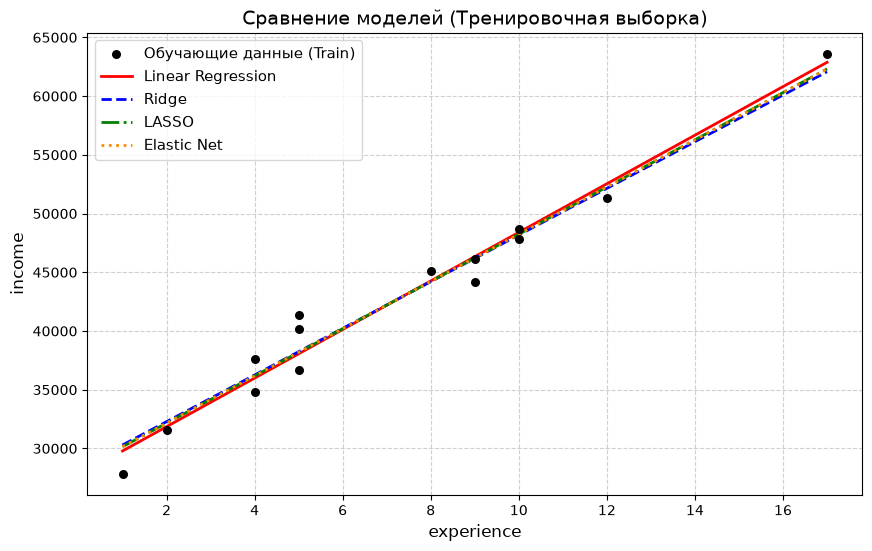

In [98]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='black', s=30, label='Обучающие данные (Train)', zorder=5)

X_line_train = np.array([[X_train.min()], [X_train.max()]])
for name, model in models.items():
    plt.plot(
        X_line_train, model.predict(X_line_train), 
        color=colors[name], 
        linestyle=linestyles[name], 
        linewidth=2, 
        label=name
    )

plt.xlabel(x_column, fontsize=12)
plt.ylabel(y_column, fontsize=12)
plt.title('Сравнение моделей (Тренировочная выборка)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

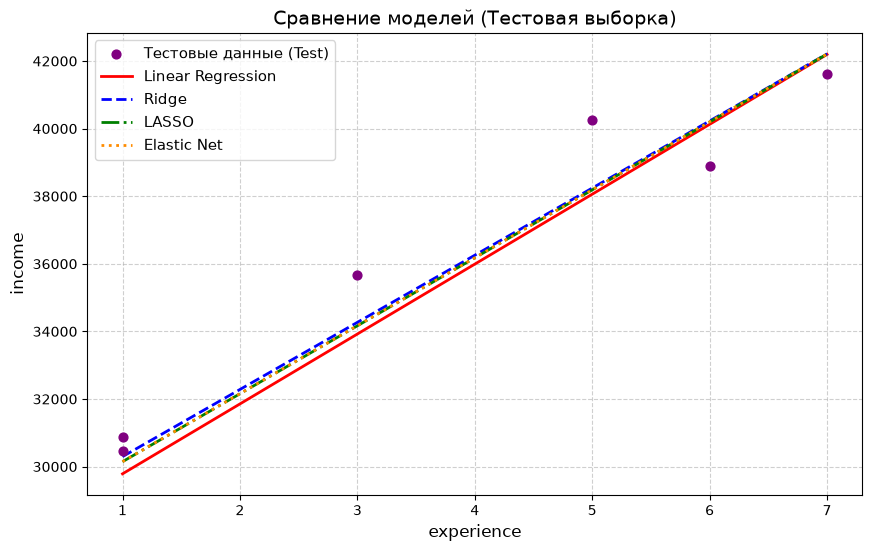

In [99]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='purple', s=40, label='Тестовые данные (Test)', zorder=5)

X_line_test = np.array([[X_test.min()], [X_test.max()]])
for name, model in models.items():
    plt.plot(
        X_line_test, model.predict(X_line_test), 
        color=colors[name], 
        linestyle=linestyles[name], 
        linewidth=2, 
        label=name
    )

plt.xlabel(x_column, fontsize=12)
plt.ylabel(y_column, fontsize=12)
plt.title('Сравнение моделей (Тестовая выборка)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [101]:
metrics_list = []

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    
    print(name)
    print("Mean Absolute Error (MAE): %.2f" % mae)
    print("Coefficient of determination (R2): %.5f" % r2)
    print("Mean Absolute Percentage Error (MAPE): %.4f\n" % mape)
    
    metrics_list.append({
        'Модель': name,
        'MAE': round(mae, 2),
        'R2': round(r2, 5),
        'MAPE': round(mape, 5),
        'MAPE (%)': round(mape * 100, 4)
    })

Linear Regression
Mean Absolute Error (MAE): 1246.57
Coefficient of determination (R2): 0.90166
Mean Absolute Percentage Error (MAPE): 0.0342

Ridge
Mean Absolute Error (MAE): 1008.51
Coefficient of determination (R2): 0.92636
Mean Absolute Percentage Error (MAPE): 0.0268

LASSO
Mean Absolute Error (MAE): 1078.78
Coefficient of determination (R2): 0.92031
Mean Absolute Percentage Error (MAPE): 0.0290

Elastic Net
Mean Absolute Error (MAE): 1077.84
Coefficient of determination (R2): 0.92039
Mean Absolute Percentage Error (MAPE): 0.0290



In [102]:
metrics_df = pd.DataFrame(metrics_list)
best_model_name = metrics_df.loc[metrics_df['R2'].idxmax(), 'Модель']
print(f"Лучшая модель по метрике R2: {best_model_name}")
metrics_df

Лучшая модель по метрике R2: Ridge


,Модель,MAE,R2,MAPE,MAPE (%)
0,Linear Regression,1246.57,0.90166,0.03425,3.4248
1,Ridge,1008.51,0.92636,0.02684,2.6842
2,LASSO,1078.78,0.92031,0.02903,2.9028
3,Elastic Net,1077.84,0.92039,0.02900,2.8999


**Итог:** Лучшей оказалась модель Ridge (наименьшая погрешность MAE и MAPE, наибольший $R^2$), это показывает эффективность применения регуляризации на небольшом наборе данных.